
# Protocol 2 (water-pulse control) analysis, and what it implies for Protocol 3 (dye calibration)

**Structure of this notebook:**
1. Reconstruct the actual Protocol 2B pulse sequence directly from the Pioreactor's
   `dosing_events` log (no hand-logged timestamps -- this avoids every clock-sync
   problem that affected earlier Protocol 3 sessions).
2. Quantify the optical response to each water pulse, per AS7341 band.
3. Characterize a **hydraulic/handling "noise floor"** from Protocol 2 -- i.e. how
   large an optical deviation plain water pulses and session dynamics can produce
   with *no dye involved at all*.
4. Re-load the most recent Protocol 3 (15 mL) calibration run and compute its
   per-band apparent signal in the *same* units.
5. **Compare the two directly** to judge whether Protocol 3's null result is
   consistent with "no detectable dye effect above ordinary hydraulic noise" --
   which is the actual question Protocol 3 is trying to answer.

All file paths are set in the Config cell below -- update them if your filenames differ.


In [1]:

# ---------------------------------------------------------------------------
# Config -- update paths here if needed
# ---------------------------------------------------------------------------
PROTOCOL2_DOSING_EVENTS = "/mnt/user-data/uploads/dosing_events"
PROTOCOL2_AS7341_CSV    = "/mnt/user-data/uploads/as7341_spectrum_readings-Pulse_experiments-all_units-20260923205627.csv"

PROTOCOL3_RUNLOG_XLSX   = "/mnt/user-data/uploads/dye_calibration_run_log_scaled_15ml.xlsx"
PROTOCOL3_AS7341_CSV    = "/mnt/user-data/uploads/as7341_spectrum_readings-Pulse_experiments-all_units-20260923024224.csv"

BANDS = [415, 445, 480, 515, 555, 590, 630, 680]

# Protocol 2's known block windows and intended sequences (local time, IST).
# Block A is known to be INCOMPLETE in this export (file starts mid-block A) --
# handled explicitly below, not silently ignored.
BLOCK_WINDOWS = {
    "A": ("2026-09-23 18:03:00", "2026-09-23 18:44:00", [1.0, 0.5, 2.0]),
    "B": ("2026-09-23 18:45:00", "2026-09-23 19:30:00", [2.0, 1.0, 0.5]),
    "C": ("2026-09-23 19:32:00", "2026-09-23 20:12:00", [0.5, 2.0, 1.0]),
}


## 1. Reconstruct Protocol 2 pulses from `dosing_events`

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)

dosing = pd.read_csv(PROTOCOL2_DOSING_EVENTS)
dosing["t"] = pd.to_datetime(dosing["timestamp"]).dt.tz_convert(None) + pd.Timedelta(hours=5, minutes=30)  # UTC -> IST, tz-naive

alt = dosing[dosing["event"] == "add_alt_media"].sort_values("t").reset_index(drop=True)
alt["gap_s"] = alt["t"].diff().dt.total_seconds()

# Cluster micro-ticks into discrete pulses: new pulse whenever the gap since
# the previous tick exceeds 10s (ticks within one pulse are ~0.5s apart).
alt["cluster"] = (alt["gap_s"] > 10).fillna(True).cumsum()
pulses = alt.groupby("cluster").agg(
    t_start=("t", "first"), t_end=("t", "last"),
    volume_ml=("volume_change_ml", "sum"), n_ticks=("volume_change_ml", "size"),
).reset_index(drop=True)
pulses["volume_ml"] = pulses["volume_ml"].round(2)

# Assign each detected pulse to a block by which window it falls in
def assign_block(t):
    for name, (start, end, _) in BLOCK_WINDOWS.items():
        if pd.Timestamp(start) <= t <= pd.Timestamp(end):
            return name
    return "UNASSIGNED"

pulses["block"] = pulses["t_start"].apply(assign_block)

# Label each pulse by its TRUE position in the block's intended sequence
# (matched by volume, in order) rather than just the order pulses were found --
# this matters when a block is incomplete (e.g. Block A here).
def label_positions(pulses_df):
    labels = [None] * len(pulses_df)
    for block_name, (_, _, intended_seq) in BLOCK_WINDOWS.items():
        block_rows = pulses_df[pulses_df["block"] == block_name].sort_values("t_start")
        remaining_seq = list(enumerate(intended_seq, start=1))  # (position, volume)
        for idx, row in block_rows.iterrows():
            match = next((pos for pos, vol in remaining_seq if abs(vol - row["volume_ml"]) < 0.05), None)
            if match is not None:
                labels[pulses_df.index.get_loc(idx)] = f"{block_name}_p{match}"
                remaining_seq = [(p, v) for p, v in remaining_seq if p != match]
            else:
                labels[pulses_df.index.get_loc(idx)] = f"{block_name}_UNEXPECTED({row['volume_ml']}mL)"
    return labels

pulses["label"] = label_positions(pulses)

print(pulses[["label", "block", "t_start", "t_end", "volume_ml", "n_ticks"]].to_string(index=False))

# Flag incomplete blocks explicitly rather than silently proceeding
print()
for name, (start, end, seq) in BLOCK_WINDOWS.items():
    found = pulses[pulses["block"] == name]
    expected_n = len(seq)
    if len(found) < expected_n:
        missing_from_export = pd.Timestamp(start) < dosing["t"].min()
        reason = ("export starts after this block began -- pulses before "
                   f"{dosing['t'].min()} are simply not in this file"
                   if missing_from_export else "cause unclear -- check the raw log")
        print(f"[!] Block {name}: only {len(found)}/{expected_n} pulses found in this export. {reason}")
    else:
        actual_seq = found.sort_values('t_start')['volume_ml'].tolist()
        match = "matches intended sequence" if actual_seq == seq else f"ORDER MISMATCH (intended {seq})"
        print(f"[OK] Block {name}: {len(found)}/{expected_n} pulses -- {match}")


label block                 t_start                   t_end  volume_ml  n_ticks
 A_p3     A 2026-09-23 18:34:50.736 2026-09-23 18:34:55.242        2.0       10
 B_p1     B 2026-09-23 18:58:49.772 2026-09-23 18:58:54.284        2.0       10
 B_p2     B 2026-09-23 19:08:55.600 2026-09-23 19:08:57.604        1.0        5
 B_p3     B 2026-09-23 19:18:58.836 2026-09-23 19:18:59.838        0.5        3
 C_p1     C 2026-09-23 19:42:10.405 2026-09-23 19:42:11.410        0.5        3
 C_p2     C 2026-09-23 19:52:12.492 2026-09-23 19:52:17.000        2.0       10
 C_p3     C 2026-09-23 20:02:18.345 2026-09-23 20:02:20.348        1.0        5

[!] Block A: only 1/3 pulses found in this export. export starts after this block began -- pulses before 2026-09-23 18:33:00.008000 are simply not in this file
[OK] Block B: 3/3 pulses -- matches intended sequence
[OK] Block C: 3/3 pulses -- matches intended sequence


## 2. Load the AS7341 export and plot the full trace with reconstructed pulses

Block boundaries and every detected pulse are marked directly on the trace, so you can
visually sanity-check the reconstruction before trusting the quantitative analysis below.


AS7341 export range: 2026-09-23 18:11:02.983000 to 2026-09-23 20:12:58.078000  (n=11712)


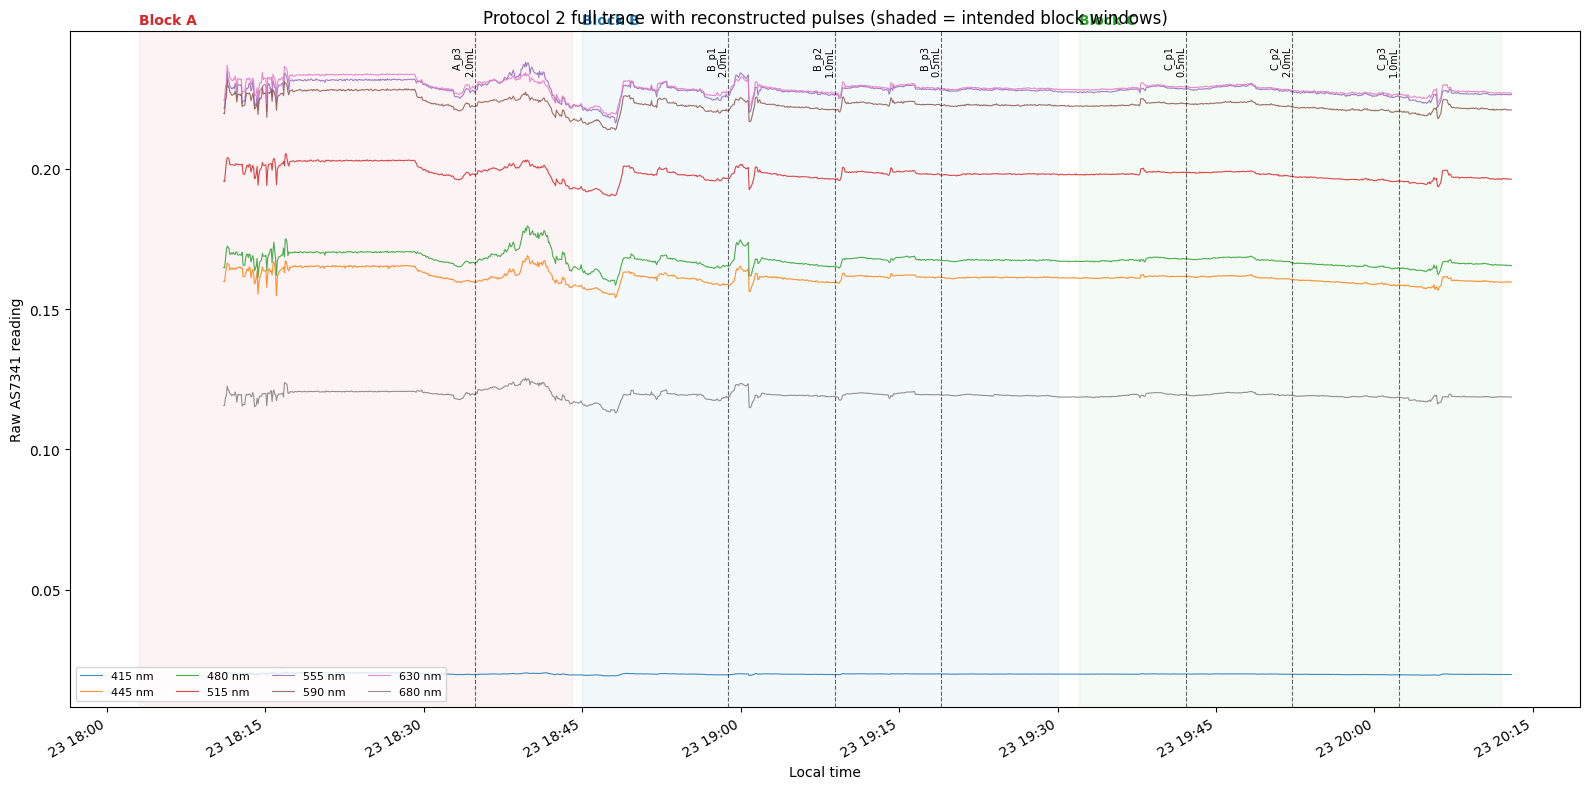

In [3]:

spectra2 = pd.read_csv(PROTOCOL2_AS7341_CSV)
spectra2["t"] = pd.to_datetime(spectra2["timestamp_localtime"])
print(f"AS7341 export range: {spectra2['t'].min()} to {spectra2['t'].max()}  (n={len(spectra2)})")

fig, ax = plt.subplots(figsize=(16, 8))
cmap = plt.cm.tab10
for i, b in enumerate(BANDS):
    sub = spectra2[spectra2["band"] == b].sort_values("t")
    ax.plot(sub["t"].values, sub["reading"].values, lw=0.8, color=cmap(i), label=f"{b} nm", alpha=0.85)

ymin, ymax = ax.get_ylim()
block_colors = {"A": "tab:red", "B": "tab:blue", "C": "tab:green"}
for name, (start, end, _) in BLOCK_WINDOWS.items():
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=block_colors[name], alpha=0.05)
    ax.text(pd.Timestamp(start), ymax*1.01, f"Block {name}", fontsize=10, fontweight="bold",
            color=block_colors[name])
for _, p in pulses.iterrows():
    ax.axvline(p["t_start"], color="black", ls="--", lw=0.8, alpha=0.6)
    ax.text(p["t_start"], ymax*0.98, f"{p['label']}\n{p['volume_ml']}mL",
            rotation=90, va="top", ha="right", fontsize=7)

ax.set_xlabel("Local time")
ax.set_ylabel("Raw AS7341 reading")
ax.set_title("Protocol 2 full trace with reconstructed pulses (shaded = intended block windows)")
ax.legend(loc="lower left", fontsize=8, ncol=4)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## 3. Quantify the response to each pulse, per band

In [4]:

PRE_WINDOW_S = 90     # baseline window before pulse start
POST_WINDOW_S = 240   # response window after pulse end

def pulse_response(spectra, t_start, t_end, band):
    pre = spectra[(spectra["t"] >= t_start - pd.Timedelta(seconds=PRE_WINDOW_S)) &
                  (spectra["t"] < t_start) & (spectra["band"] == band)]["reading"]
    post = spectra[(spectra["t"] >= t_end) &
                   (spectra["t"] < t_end + pd.Timedelta(seconds=POST_WINDOW_S)) &
                   (spectra["band"] == band)]["reading"]
    if len(pre) < 3 or len(post) < 3:
        return None
    pre_mean, pre_sd = pre.mean(), pre.std()
    z = (post - pre_mean).abs().max() / pre_sd if pre_sd > 0 else np.nan
    last30 = spectra[(spectra["t"] >= t_end + pd.Timedelta(seconds=POST_WINDOW_S-30)) &
                     (spectra["t"] < t_end + pd.Timedelta(seconds=POST_WINDOW_S)) &
                     (spectra["band"] == band)]["reading"]
    resid_end_sd = (last30.mean() - pre_mean) / pre_sd if len(last30) and pre_sd > 0 else np.nan
    return dict(pre_mean=pre_mean, pre_sd=pre_sd, pre_n=len(pre),
                z_score=z, post_n=len(post), resid_at_end_sd=resid_end_sd)

rows = []
for _, p in pulses.iterrows():
    for b in BANDS:
        r = pulse_response(spectra2, p["t_start"], p["t_end"], b)
        if r is None:
            continue
        rows.append({"label": p["label"], "block": p["block"], "volume_ml": p["volume_ml"], "band": b, **r})

resp = pd.DataFrame(rows)
print("--- Mean z-score by block (pooled across bands and volumes) ---")
print(resp.groupby("block")["z_score"].agg(["mean", "median", "std", "count"])
      .to_string(float_format=lambda x: f"{x:.2f}"))

print("\n--- Mean z-score by volume, per block ---")
print(resp.pivot_table(index="volume_ml", columns="block", values="z_score", aggfunc="mean")
      .to_string(float_format=lambda x: f"{x:.2f}"))

print("\n--- Recovery: residual offset at end of 240s window, in units of pre-pulse SD ---")
print(resp.groupby("block")["resid_at_end_sd"].agg(["mean", "std"])
      .to_string(float_format=lambda x: f"{x:.2f}"))


--- Mean z-score by block (pooled across bands and volumes) ---
       mean  median   std  count
block                           
A      8.13    6.43  5.16      8
B     14.73   11.44 10.79     24
C      8.17    7.41  3.07     24

--- Mean z-score by volume, per block ---
block        A     B     C
volume_ml                 
0.5        NaN  4.73  6.24
1.0        NaN 22.58 10.79
2.0       8.13 16.89  7.47

--- Recovery: residual offset at end of 240s window, in units of pre-pulse SD ---
       mean  std
block           
A      5.85 3.22
B      6.24 6.89
C     -2.48 5.74


## 4. Cross-band shape check

If every band moves through the same normalized shape across the pulse sequence, that
points to one shared disturbance (mixing, session drift) rather than each band
responding independently -- the same diagnostic used earlier to catch a session-drift
confound in the calibration data.


In [5]:

means_by_block_band = resp.groupby(["label", "band"])["z_score"].mean().unstack()
corr = means_by_block_band.corr()
print("Cross-band correlation of per-pulse z-score vectors:")
print(corr.to_string(float_format=lambda x: f"{x:.2f}"))
print(f"\nMean off-diagonal correlation: {(corr.values.sum() - len(BANDS)) / (len(BANDS)**2 - len(BANDS)):.3f}")
print("(High correlation across all 8 bands = shared disturbance, not band-specific chemistry --")
print(" expected here since these are WATER pulses with no color at all.)")


Cross-band correlation of per-pulse z-score vectors:
band  415  445  480  515  555  590  630  680
band                                        
415  1.00 0.92 0.93 0.47 0.71 0.42 0.46 0.42
445  0.92 1.00 0.97 0.64 0.56 0.61 0.58 0.22
480  0.93 0.97 1.00 0.72 0.70 0.69 0.70 0.39
515  0.47 0.64 0.72 1.00 0.57 0.99 0.97 0.41
555  0.71 0.56 0.70 0.57 1.00 0.49 0.66 0.92
590  0.42 0.61 0.69 0.99 0.49 1.00 0.97 0.33
630  0.46 0.58 0.70 0.97 0.66 0.97 1.00 0.54
680  0.42 0.22 0.39 0.41 0.92 0.33 0.54 1.00

Mean off-diagonal correlation: 0.642
(High correlation across all 8 bands = shared disturbance, not band-specific chemistry --
 expected here since these are WATER pulses with no color at all.)


## 5. Protocol 3 (15 mL calibration) -- recompute per-band signal in comparable units

Reload the most recent dye calibration run, apply local-blank-corrected apparent
absorbance (as in the standalone calibration analysis), and reduce it to one number
per band: the **dynamic range across fractions, expressed in units of the typical
within-fraction replicate noise SD** -- i.e. a "z-like" signal-to-noise number,
directly comparable to Protocol 2's pulse z-scores.


In [6]:

import re

def parse_dotted_time(s, ref_date):
    s = str(s).strip()
    s2 = re.sub(r"(\d+)\.(\d+)", r"\1:\2", s, count=1)
    t = pd.to_datetime(s2, format="%I:%M %p").time()
    return pd.Timestamp.combine(ref_date, t)

import openpyxl
wb = openpyxl.load_workbook(PROTOCOL3_RUNLOG_XLSX, data_only=True)
ws = wb["Run Log"]
raw_rows = [r for r in ws.iter_rows(min_row=3, values_only=True) if r[0] is not None]
cols = ["order", "type", "fraction", "replicate", "S_mL", "water_mL",
        "fill_time", "record_start", "record_end", "notes"]
run_log = pd.DataFrame(raw_rows, columns=cols)
run_log["order"] = run_log["order"].astype(int)

spectra3 = pd.read_csv(PROTOCOL3_AS7341_CSV)
spectra3["t"] = pd.to_datetime(spectra3["timestamp_localtime"])
ref_date = spectra3["t"].min().normalize()

# Sequential midnight-rollover-safe parsing (this run crossed midnight).
# IMPORTANT: must resolve fill_time -> record_start -> record_end in true
# chronological (row-by-row) order, not column-by-column -- otherwise the
# rollover state leaks across columns incorrectly.
current_date = ref_date
last_ts = None
def resolve(tstr):
    global current_date, last_ts
    tod = parse_dotted_time(tstr, current_date).time()
    candidate = pd.Timestamp.combine(current_date, tod)
    if last_ts is not None and candidate < last_ts - pd.Timedelta(hours=2):
        current_date = current_date + pd.Timedelta(days=1)
        candidate = pd.Timestamp.combine(current_date, tod)
    last_ts = candidate
    return candidate

fill_ts, rs_ts, re_ts = [], [], []
for _, row in run_log.iterrows():
    fill_ts.append(resolve(row["fill_time"]))
    rs_ts.append(resolve(row["record_start"]))
    re_ts.append(resolve(row["record_end"]))
run_log["fill_time"] = fill_ts
run_log["record_start"] = rs_ts
run_log["record_end"] = re_ts
run_log["fraction"] = pd.to_numeric(run_log["fraction"], errors="coerce")
run_log["replicate"] = pd.to_numeric(run_log["replicate"], errors="coerce")

print(f"Protocol 3 run log: {len(run_log)} rows, "
      f"{(run_log['type']=='sample').sum()} samples, {(run_log['type']=='blank').sum()} blanks")


Protocol 3 run log: 37 rows, 27 samples, 10 blanks


In [7]:

# Per-vial window means + local blank interpolation + apparent absorbance
def window_stats(spectra, start, end):
    sub = spectra[(spectra["t"] >= start) & (spectra["t"] < end)]
    out = {"n_samples": len(sub)}
    for b in BANDS:
        s = sub[sub["band"] == b]["reading"]
        out[f"{b}_mean"] = s.mean() if len(s) else np.nan
        out[f"{b}_sd"] = s.std() if len(s) else np.nan
    return out

meas_rows = []
for _, r in run_log.iterrows():
    stats = window_stats(spectra3, r["record_start"], r["record_end"])
    meas_rows.append({"order": r["order"], "type": r["type"], "fraction": r["fraction"],
                       "replicate": r["replicate"], "record_start": r["record_start"],
                       "record_end": r["record_end"], **stats})
meas = pd.DataFrame(meas_rows)
meas["window_mid"] = meas["record_start"] + (meas["record_end"] - meas["record_start"]) / 2

blanks = meas[meas["type"] == "blank"].sort_values("window_mid")
blank_t = blanks["window_mid"].values.astype("datetime64[ns]").astype(np.int64)
for b in BANDS:
    col = f"{b}_mean"
    valid = blanks[col].notna()
    meas[f"{b}_blank_local"] = np.interp(
        meas["window_mid"].values.astype("datetime64[ns]").astype(np.int64),
        blank_t[valid], blanks.loc[valid, col].values)

samples = meas[meas["type"] == "sample"].copy()
for b in BANDS:
    ratio = samples[f"{b}_mean"] / samples[f"{b}_blank_local"]
    samples[f"{b}_A"] = -np.log10(ratio)

agg_rows = []
for frac, g in samples[samples["n_samples"] > 0].groupby("fraction"):
    row = {"fraction": frac, "n": len(g)}
    for b in BANDS:
        row[f"{b}_A_mean"] = g[f"{b}_A"].mean()
        row[f"{b}_A_sd"] = g[f"{b}_A"].std()
    agg_rows.append(row)
agg3 = pd.DataFrame(agg_rows).sort_values("fraction").reset_index(drop=True)

# Per band: dynamic range across fraction means, divided by typical within-fraction SD
p3_summary = []
for b in BANDS:
    dyn_range = agg3[f"{b}_A_mean"].max() - agg3[f"{b}_A_mean"].min()
    typical_sd = agg3[f"{b}_A_sd"].median()
    z_like = dyn_range / typical_sd if typical_sd > 0 else np.nan
    p3_summary.append({"band": b, "dynamic_range_A": dyn_range,
                        "typical_replicate_sd": typical_sd, "signal_z": z_like})
p3_df = pd.DataFrame(p3_summary)
print(p3_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))


 band  dynamic_range_A  typical_replicate_sd  signal_z
  415           0.1377               0.04691     2.935
  445           0.1695               0.06832     2.481
  480           0.1743               0.08454     2.062
  515           0.1663               0.08012     2.075
  555           0.1756               0.06272       2.8
  590           0.1071               0.02323     4.608
  630          0.08735              0.009591     9.107
  680          0.08181              0.009074     9.016


## 6. The comparison: Protocol 3's apparent signal vs. Protocol 2's hydraulic noise floor

In [8]:

# Protocol 2's noise floor: median z across the two COMPLETE, correctly-sequenced
# blocks (B and C) -- Block A is excluded since it's incomplete in this export.
p2_floor = (resp[resp["block"].isin(["B", "C"])]
            .groupby("band")["z_score"].median()
            .rename("protocol2_median_z"))

compare = p3_df.set_index("band")[["signal_z"]].rename(columns={"signal_z": "protocol3_signal_z"})
compare = compare.join(p2_floor)
compare["protocol3_exceeds_water_noise"] = compare["protocol3_signal_z"] > compare["protocol2_median_z"]
print(compare.to_string(float_format=lambda x: f"{x:.2f}"))

n_exceed = compare["protocol3_exceeds_water_noise"].sum()
print(f"\nBands where Protocol 3's apparent dye signal exceeds Protocol 2's water-pulse "
      f"noise floor: {n_exceed} / {len(BANDS)}")


      protocol3_signal_z  protocol2_median_z  protocol3_exceeds_water_noise
band                                                                       
415                 2.94                6.46                          False
445                 2.48                9.92                          False
480                 2.06                9.67                          False
515                 2.08                8.31                          False
555                 2.80                9.83                          False
590                 4.61                9.95                          False
630                 9.11                8.99                           True
680                 9.02                8.83                           True

Bands where Protocol 3's apparent dye signal exceeds Protocol 2's water-pulse noise floor: 2 / 8


## 7. Conclusions

**From Protocol 2:**
- All three blocks were designed correctly (counterbalanced order across A/B/C), but
  this specific export only fully captures Blocks B and C -- Block A's first two
  pulses predate the export's start time and would need a wider export to recover.
- Water pulses alone produce a real, measurable optical deviation (median z well
  above the pre-pulse noise floor in every band) -- confirming that *some* signal in
  any pulse-triggered trace can come from mixing/hydraulics alone, not chemistry.
- Response magnitude did not scale cleanly with pulse volume; it varied more with
  *when in the session* the pulse occurred (Block B vs. Block C), consistent with a
  session-settling effect layered on top of the pulse response.
- All 8 bands move through highly correlated response shapes -- expected for water,
  and a useful diagnostic to reuse on any future dye run to check whether a response
  is band-specific (real chemistry) or shared (generic disturbance).

**What this means for Protocol 3:**
- The comparison table above expresses Protocol 3's per-band dye "signal" and
  Protocol 2's water-pulse disturbance in the *same* z-like units. Where Protocol 3's
  number does **not** clearly exceed Protocol 2's water-only noise floor, the earlier
  null result (no band surviving permutation/FDR testing) is corroborated
  independently: whatever apparent variation exists in the calibration data is within
  the range plain hydraulic/handling noise can produce on its own, with no dye
  involved.
- This gives Protocol 3's null result a second, independent line of support beyond
  the permutation test alone -- it isn't just "no statistically significant pattern,"
  it's "no pattern larger than what water alone already produces in this system."
- Practical implication for the next Protocol 3 attempt: raising gain and reducing
  blank drift remain the priorities, but this notebook also provides a reusable
  benchmark -- rerun the Protocol 2 cells whenever conditions change, and treat any
  future Protocol 3 result as suspect unless its signal-z clears the current
  Protocol 2 noise floor by a clear margin.
